In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import urllib.request

In [19]:


data_dir = 'data'
if not os.path.exists(data_dir):
    os.makedirs(data_dir)
    print(f"Created directory: {data_dir}/")


base_url = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/"
files_to_download = [
    "DEMO_L.xpt",
    "BMX_L.xpt",
    "BPXO_L.xpt",
    "SLQ_L.xpt",
    "PAQ_L.xpt"
]


print("Downloading NHANES 2021-2023 data...")
for file_name in files_to_download:
    file_path = os.path.join(data_dir, file_name)
    file_url = base_url + file_name


    if not os.path.exists(file_path):
        print(f"  Downloading {file_name} from {file_url}...")
        try:
            urllib.request.urlretrieve(file_url, file_path)
            print(f"  -> Successfully saved to {file_path}")
        except Exception as e:
            print(f"  -> Error downloading {file_name}: {e}")
    else:
        print(f"  {file_name} already exists in {data_dir}/. Skipping download.")


print("\nLoading data into Pandas DataFrames...")
try:
    demo = pd.read_sas(f'{data_dir}/DEMO_L.xpt')
    bmx  = pd.read_sas(f'{data_dir}/BMX_L.xpt')
    bpxo = pd.read_sas(f'{data_dir}/BPXO_L.xpt')
    slq  = pd.read_sas(f'{data_dir}/SLQ_L.xpt')
    paq  = pd.read_sas(f'{data_dir}/PAQ_L.xpt')

    print("\n✅ All data loaded successfully!")
    print(f"DEMO rows: {demo.shape[0]}")

except Exception as e:
    print(f"Error reading the files: {e}")

  DEMO_L.xpt already exists in data/. Skipping download.
  BMX_L.xpt already exists in data/. Skipping download.
  BPXO_L.xpt already exists in data/. Skipping download.
  SLQ_L.xpt already exists in data/. Skipping download.
  PAQ_L.xpt already exists in data/. Skipping download.

Loading data into Pandas DataFrames...

✅ All data loaded successfully!
DEMO rows: 11933


In [20]:
print(f"Total individuals before merging all files: {demo.shape[0]}")

# We use 'inner' join to keep only people who exist in all these files
df = demo.merge(bmx, on='SEQN', how='inner')
df = df.merge(bpxo, on='SEQN', how='inner')
df = df.merge(slq, on='SEQN', how='inner')
df = df.merge(paq, on='SEQN', how='inner')

print(f"Total individuals after merging all files: {df.shape[0]}")

# Keep only the columns we actually need for our analysis to save memory
columns_to_keep = [
    'SEQN',       # ID
    'RIDAGEYR',   # Age (years)
    'RIAGENDR',   # Gender (1=Male, 2=Female)
    'WTMEC2YR',   # MEC Exam Weight
    'BMXBMI',     # Body Mass Index (BMI)
    'BPXOSY1',    # Systolic Blood pressure (1st reading)
    'SLD012',     # Sleep hours
    'PAD680'      # Minutes of Sedentary activity(how many minutes do you spend sitting.)
]

df = df[columns_to_keep].copy()

Total individuals before merging all files: 11933
Total individuals after merging all files: 6337


In [21]:
# Convert NHANES "Refused" or "Don't Know" codes to NaN

# Sedentary activity minutes: 7777, 9999 mean refused/don't know
df['PAD680'] = df['PAD680'].replace([7777, 9999], np.nan)


# Rename columns to human-readable names
df = df.rename(columns={
    'RIDAGEYR': 'Age',
    'RIAGENDR': 'Gender',
    'WTMEC2YR': 'Weight',
    'BMXBMI': 'BMI',
    'BPXOSY1': 'Systolic_BP',
    'SLD012': 'Sleep_Hours',
    'PAD680': 'Sedentary_Min'
})

# Make Gender categorical
df['Gender'] = df['Gender'].map({1.0: 'Male', 2.0: 'Female'})

# Print missing data count before dropping
print("Missing values per column before cleaning:")
print(df.isnull().sum())

Missing values per column before cleaning:
SEQN               0
Age                0
Gender             0
Weight             0
BMI              102
Systolic_BP      214
Sleep_Hours       65
Sedentary_Min     47
dtype: int64


In [22]:
initial_count = df.shape[0]

# Keep only adults (Age >= 20)
df_adults = df[df['Age'] >= 20].copy()
dropped_children = initial_count - df_adults.shape[0]

# Drop rows missing our main target variables
df_final = df_adults.dropna(subset=['Systolic_BP', 'BMI', 'Sleep_Hours', 'Sedentary_Min']).copy()
dropped_missing = df_adults.shape[0] - df_final.shape[0]

print(f"Dropped {dropped_children} individuals aged under 20.")
print(f"Dropped {dropped_missing} individuals missing key health data.")
print(f"Final Analytical Population Size: {df_final.shape[0]}")

Dropped 273 individuals aged under 20.
Dropped 350 individuals missing key health data.
Final Analytical Population Size: 5714


In [23]:
# Center and Spread for Quantitative Variables
quant_vars = ['Age', 'BMI', 'Systolic_BP', 'Sleep_Hours', 'Sedentary_Min']
summary_stats = df_final[quant_vars].describe().T
summary_stats['IQR'] = summary_stats['75%'] - summary_stats['25%']
summary_stats = summary_stats.round(2)
print("\n--- Quantitative Variables Summary ---")
print(summary_stats[['mean', '50%', 'std', 'min', 'max', 'IQR', '25%', '75%']])


# Frequency Tables for Categorical Variables
print("\n--- Gender Frequency Table ---")
freq_table = df_final['Gender'].value_counts()
perc_table = df_final['Gender'].value_counts(normalize=True) * 100
freq_df = pd.DataFrame({'Count': freq_table, 'Percentage (%)': perc_table})
print(freq_df)


--- Quantitative Variables Summary ---
                 mean    50%     std   min     max    IQR    25%    75%
Age             53.75   57.0   17.09  20.0    80.0   29.0   39.0   68.0
BMI             29.74   28.4    7.16  11.1    68.9    8.8   24.7   33.5
Systolic_BP    123.00  121.0   18.47  75.0   225.0   23.0  110.0  133.0
Sleep_Hours      7.70    8.0    1.57   2.0    14.0    1.5    7.0    8.5
Sedentary_Min  363.94  300.0  208.81   0.0  1380.0  300.0  180.0  480.0

--- Gender Frequency Table ---
        Count  Percentage (%)
Gender                       
Female   3143        55.00525
Male     2571        44.99475


/tmp/ipykernel_1283/4181775284.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Gender', y='Systolic_BP', data=df_final, palette='Set2')


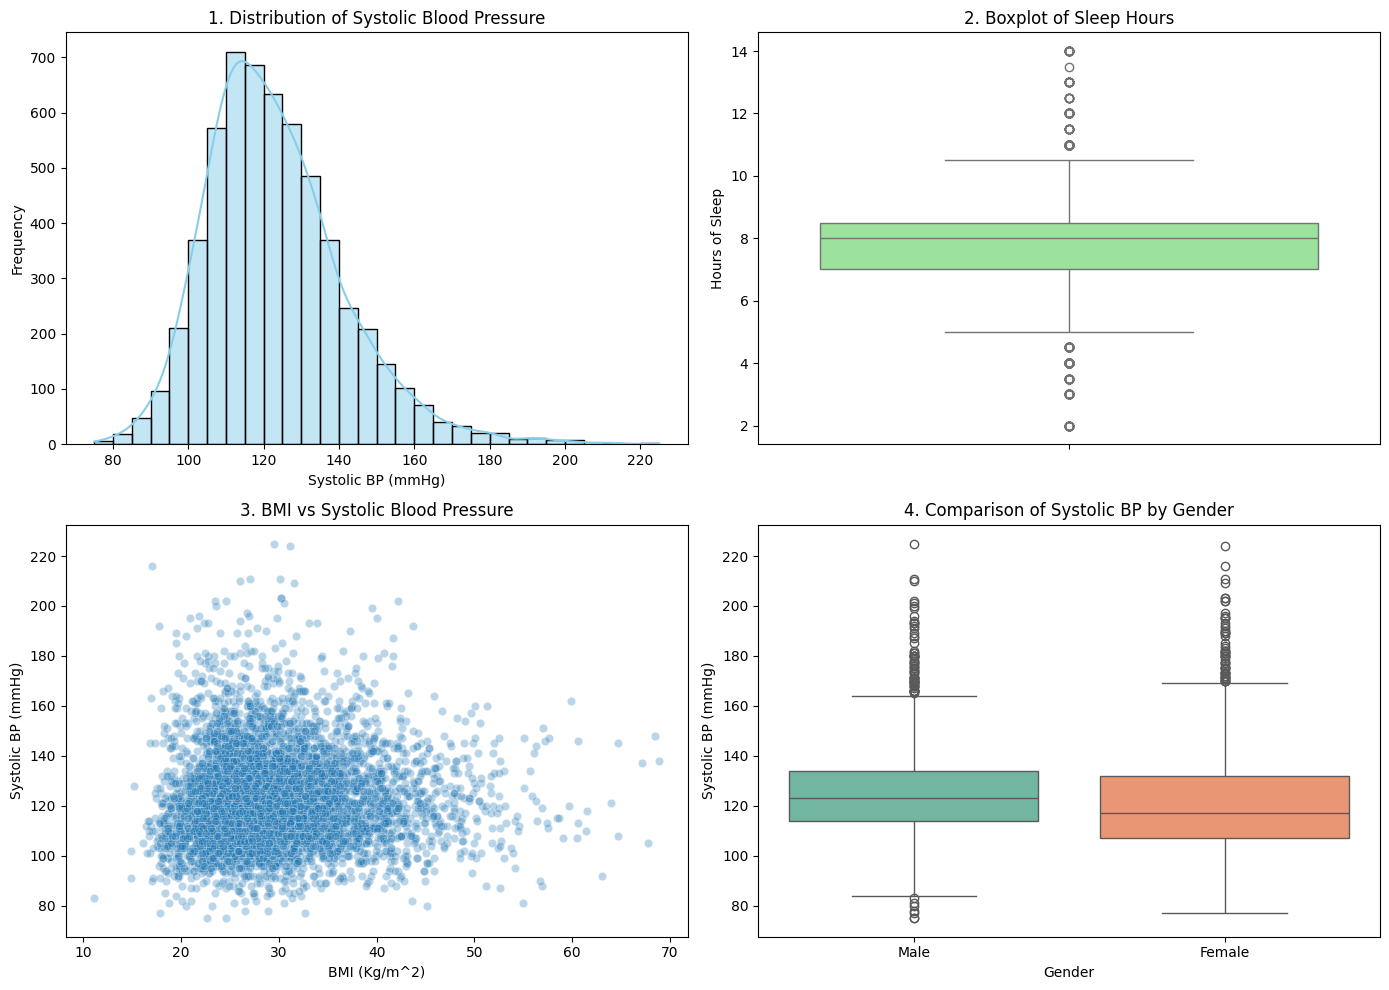

In [24]:
plt.figure(figsize=(14, 10))

# Plot 1: Histogram of target variable (Systolic BP) - checks distribution (Task 8)
plt.subplot(2, 2, 1)
sns.histplot(df_final['Systolic_BP'], bins=30, kde=True, color='skyblue')
plt.title('1. Distribution of Systolic Blood Pressure')
plt.xlabel('Systolic BP (mmHg)')
plt.ylabel('Frequency')

# Plot 2: Boxplot of Sleep Hours - checks outliers and spread (Task 8)
plt.subplot(2, 2, 2)
sns.boxplot(y=df_final['Sleep_Hours'], color='lightgreen')
plt.title('2. Boxplot of Sleep Hours')
plt.ylabel('Hours of Sleep')

# Plot 3: Scatter plot (BMI vs Blood Pressure) - checks relationships (Task 8)
plt.subplot(2, 2, 3)
sns.scatterplot(x='BMI', y='Systolic_BP', data=df_final, alpha=0.3)
plt.title('3. BMI vs Systolic Blood Pressure')
plt.xlabel('BMI (Kg/m^2)')
plt.ylabel('Systolic BP (mmHg)')

# Plot 4: Descriptive Comparison (Task 9) - Blood pressure across Gender
plt.subplot(2, 2, 4)
sns.boxplot(x='Gender', y='Systolic_BP', data=df_final, palette='Set2')
plt.title('4. Comparison of Systolic BP by Gender')
plt.xlabel('Gender')
plt.ylabel('Systolic BP (mmHg)')

plt.tight_layout()
plt.show()

In [25]:
print("\n--- Descriptive Comparison of Systolic BP by Gender ---")
gender_bp_summary = df_final.groupby('Gender')['Systolic_BP'].agg(['count', 'mean', 'std', 'median', lambda x: x.quantile(0.75) - x.quantile(0.25)])
gender_bp_summary.columns = ['Count', 'Mean', 'Std Dev', 'Median', 'IQR']
print(gender_bp_summary.round(2))


--- Descriptive Comparison of Systolic BP by Gender ---
        Count    Mean  Std Dev  Median   IQR
Gender                                      
Female   3143  120.86    19.23   117.0  25.0
Male     2571  125.61    17.13   123.0  20.0


In [26]:
# --- Raw vs Weighted Summaries ---
raw_mean_bp = df_final['Systolic_BP'].mean()
weighted_mean_bp = np.average(df_final['Systolic_BP'], weights=df_final['Weight'])

raw_mean_age = df_final['Age'].mean()
weighted_mean_age = np.average(df_final['Age'], weights=df_final['Weight'])

print(f"Systolic BP Mean -> Raw: {raw_mean_bp:.2f} mmHg | Weighted: {weighted_mean_bp:.2f} mmHg")
print(f"Age Mean         -> Raw: {raw_mean_age:.2f} years | Weighted: {weighted_mean_age:.2f} years")

Systolic BP Mean -> Raw: 123.00 mmHg | Weighted: 121.22 mmHg
Age Mean         -> Raw: 53.75 years | Weighted: 48.78 years
